# Titanic Survival Prediction: Comparing Multiple ML Models

**Goal:** Predict whether a passenger survived using several Scikit-learn models and compare them fairly.

**Workflow:** Load data → EDA → Feature engineering → Preprocessing pipeline → Train multiple models → Cross-validation → Test evaluation → Hyperparameter tuning → Save best model

**Tools:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn

## 1. Imports

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the Data

The cell below looks for the Kaggle `train.csv` first (Kaggle notebook path, then the current folder).
If it is not found, it downloads a public copy of the Titanic dataset.

To use the official Kaggle file: download `train.csv` from the Kaggle *Titanic - Machine Learning from Disaster* competition and put it next to this notebook.

In [3]:
import os

candidates = ["/kaggle/input/competitions/titanic/train.csv", "train.csv", "titanic.csv"]
path = next((p for p in candidates if os.path.exists(p)), None)

if path:
    df = pd.read_csv(path)
    print(f"Loaded local file: {path}")
else:
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df = pd.read_csv(url)
    print("Loaded public copy from GitHub")

print(df.shape)
df.head()

Loaded local file: /kaggle/input/competitions/titanic/train.csv
(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Exploratory Data Analysis (EDA)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Missing values
missing = df.isnull().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(df) * 100).round(1)
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,percent
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


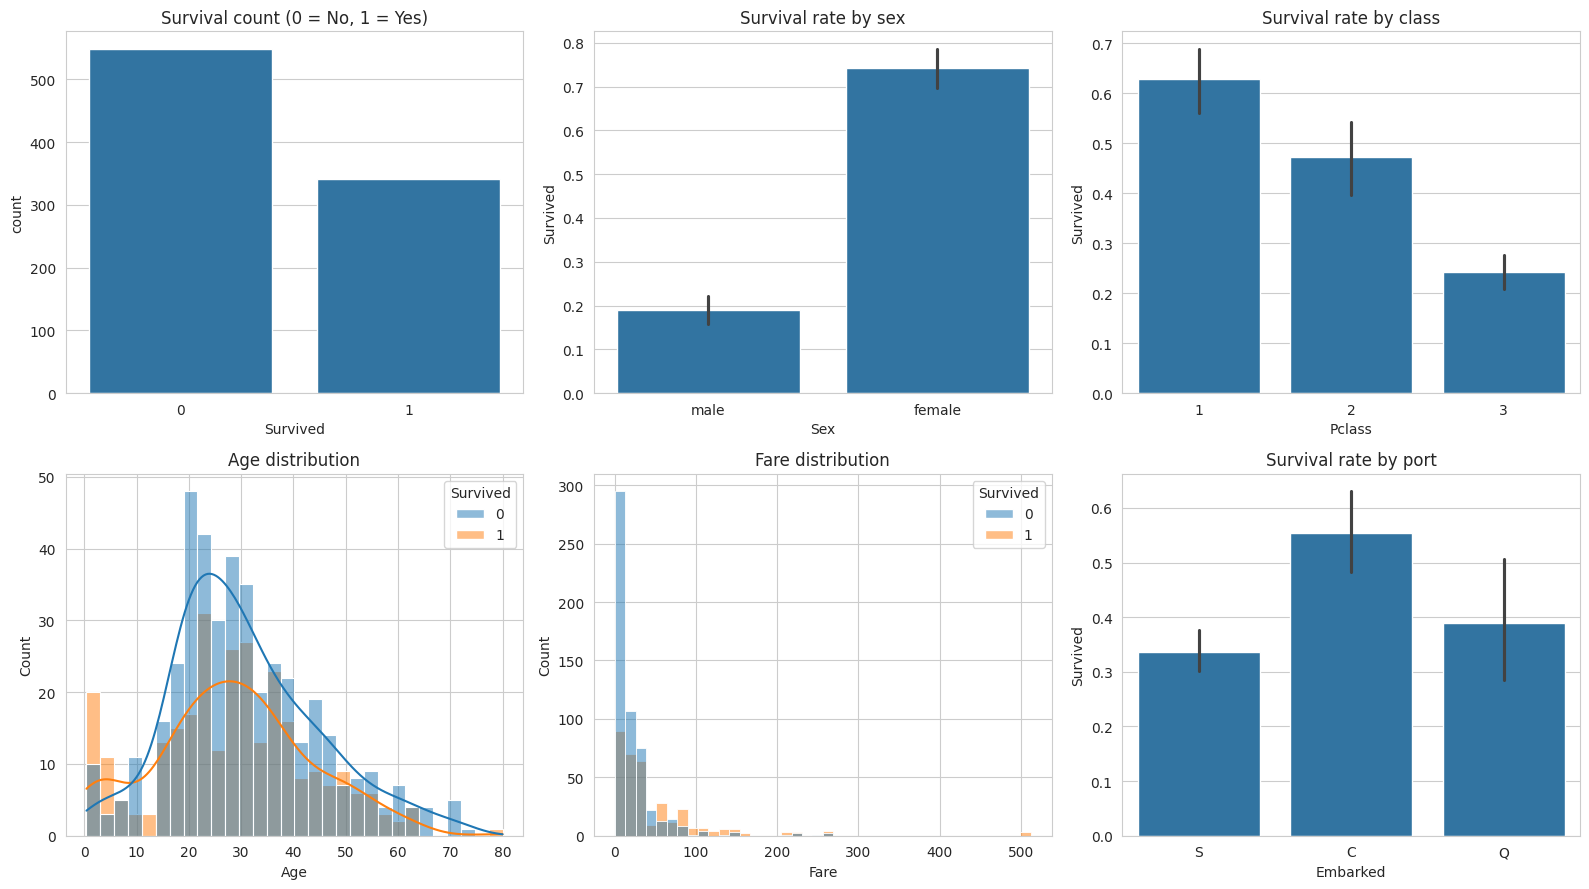

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(data=df, x="Survived", ax=axes[0, 0]); axes[0, 0].set_title("Survival count (0 = No, 1 = Yes)")
sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0, 1]); axes[0, 1].set_title("Survival rate by sex")
sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[0, 2]); axes[0, 2].set_title("Survival rate by class")
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[1, 0]); axes[1, 0].set_title("Age distribution")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axes[1, 1]); axes[1, 1].set_title("Fare distribution")
sns.barplot(data=df, x="Embarked", y="Survived", ax=axes[1, 2]); axes[1, 2].set_title("Survival rate by port")

plt.tight_layout()
plt.show()

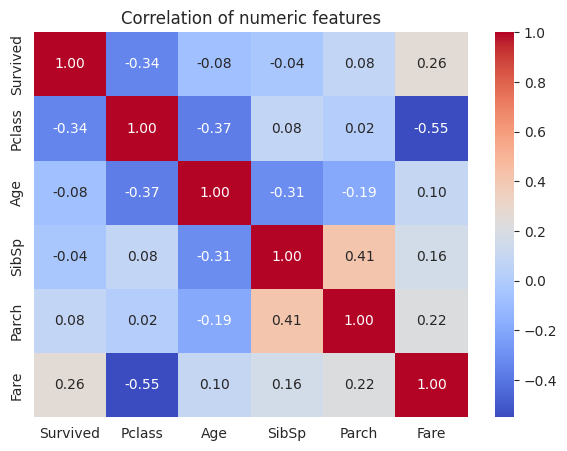

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").drop(columns="PassengerId", errors="ignore").corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation of numeric features")
plt.show()

## 4. Feature Engineering

New features that usually help on Titanic:
- **Title** extracted from the name (Mr, Mrs, Miss, Master, Rare)
- **FamilySize** = SibSp + Parch + 1
- **IsAlone** = travelling without family
- **HasCabin** = whether a cabin number was recorded (a proxy for wealth)

Each of these is computed row by row, so there is no data leakage.

In [10]:
def engineer_features(data):
    d = data.copy()

    # Title from name
    d["Title"] = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
    d["Title"] = d["Title"].replace(title_map)
    common = ["Mr", "Mrs", "Miss", "Master"]
    d["Title"] = d["Title"].where(d["Title"].isin(common), "Rare")

    # Family features
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)

    # Cabin known?
    d["HasCabin"] = d["Cabin"].notnull().astype(int)

    # Drop columns that are not useful for modelling
    d = d.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")
    return d

data = engineer_features(df)
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,1,1,0


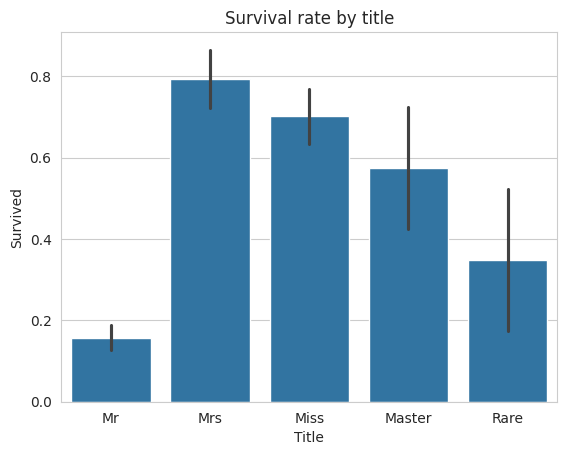

In [11]:
sns.barplot(data=data, x="Title", y="Survived")
plt.title("Survival rate by title")
plt.show()

## 5. Train/Test Split and Preprocessing Pipeline

- The data is split **before** any fitting so that the test set stays unseen.
- Imputation and scaling live inside a `Pipeline`, so they are learned only from training folds (no leakage during cross-validation).

In [12]:
X = data.drop(columns="Survived")
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate (train):", round(y_train.mean(), 3), "| (test):", round(y_test.mean(), 3))

Train: (712, 11) | Test: (179, 11)
Survival rate (train): 0.383 | (test): 0.385


In [13]:
numeric_features = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
categorical_features = ["Pclass", "Sex", "Embarked", "Title", "IsAlone", "HasCabin"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Fare', 'SibSp', 'Parch',
                                  'FamilySize']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Pclass', 'Sex', 'Embarked', 'Title',
                                  'IsAlone', 'HasCabin'])])

## 6. Define the Models

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
}

pipelines = {
    name: Pipeline([("prep", preprocessor), ("model", model)])
    for name, model in models.items()
}
list(pipelines)

['Logistic Regression',
 'KNN',
 'SVM (RBF)',
 'Decision Tree',
 'Random Forest',
 'Gradient Boosting',
 'AdaBoost']

## 7. Compare Models with Cross-Validation

5-fold stratified cross-validation on the **training set** gives a more reliable estimate than a single split.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "Model": name,
        "Accuracy": res["test_accuracy"].mean(),
        "Accuracy Std": res["test_accuracy"].std(),
        "Precision": res["test_precision"].mean(),
        "Recall": res["test_recall"].mean(),
        "F1": res["test_f1"].mean(),
        "ROC-AUC": res["test_roc_auc"].mean(),
    })

cv_results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
cv_results.round(4)

,Model,Accuracy,Accuracy Std,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8273,0.0237,0.7901,0.7547,0.7707,0.8711
1,SVM (RBF),0.8273,0.0149,0.8059,0.7253,0.7630,0.8612
2,Gradient Boosting,0.8244,0.0242,0.8045,0.7290,0.7615,0.8965
3,AdaBoost,0.8202,0.0303,0.7610,0.7803,0.7695,0.8669
4,Random Forest,0.8146,0.0111,0.7604,0.7546,0.7574,0.8733
5,Decision Tree,0.8118,0.0127,0.7846,0.7071,0.7420,0.8567
6,KNN,0.8076,0.0199,0.7875,0.6887,0.7334,0.8560


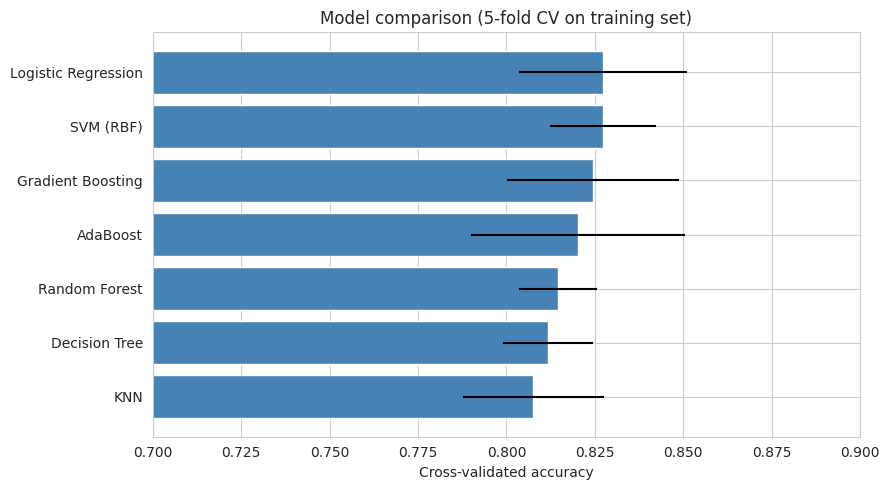

In [16]:
plt.figure(figsize=(9, 5))
order = cv_results.sort_values("Accuracy")
plt.barh(order["Model"], order["Accuracy"], xerr=order["Accuracy Std"], color="steelblue")
plt.xlim(0.7, 0.9)
plt.xlabel("Cross-validated accuracy")
plt.title("Model comparison (5-fold CV on training set)")
plt.tight_layout()
plt.show()

## 8. Evaluate All Models on the Held-Out Test Set

In [17]:
test_rows = []
fitted = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

test_results = pd.DataFrame(test_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
test_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,SVM (RBF),0.8380,0.8125,0.7536,0.7820,0.8387
1,Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8726
2,Gradient Boosting,0.8268,0.8167,0.7101,0.7597,0.8423
3,AdaBoost,0.8045,0.7297,0.7826,0.7552,0.8217
4,Random Forest,0.8045,0.7576,0.7246,0.7407,0.8231
5,KNN,0.7821,0.7586,0.6377,0.6929,0.8520
6,Decision Tree,0.7821,0.8000,0.5797,0.6723,0.8362


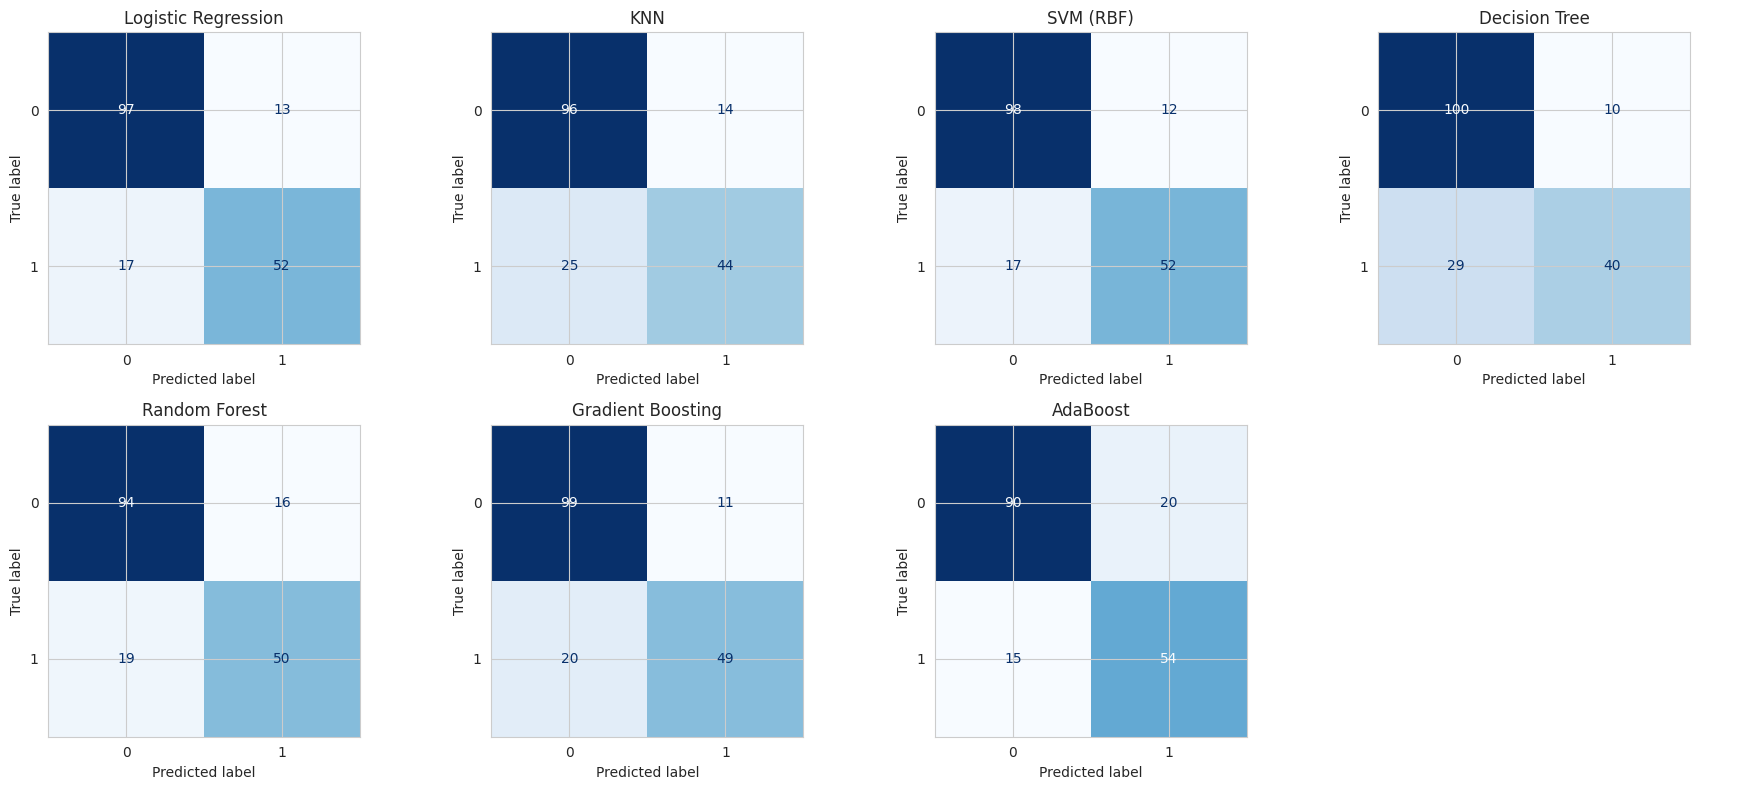

In [18]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
for ax in axes[len(fitted):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Hyperparameter Tuning (Random Forest)

Tuning with `GridSearchCV` on the training set only. You can swap in whichever model won in Section 7.

In [19]:
rf_pipe = Pipeline([("prep", preprocessor),
                    ("model", RandomForestClassifier(random_state=RANDOM_STATE))])

param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
}

grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best CV accuracy:", round(grid.best_score_, 4))
print("Best params:", grid.best_params_)

Best CV accuracy: 0.8357
Best params: {'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 400}


In [20]:
best_model = grid.best_estimator_
pred = best_model.predict(X_test)

print(f"Tuned Random Forest, test accuracy: {accuracy_score(y_test, pred):.4f}")
print()
print(classification_report(y_test, pred, target_names=["Did not survive", "Survived"]))

Tuned Random Forest, test accuracy: 0.7933

                 precision    recall  f1-score   support

Did not survive       0.81      0.87      0.84       110
       Survived       0.77      0.67      0.71        69

       accuracy                           0.79       179
      macro avg       0.79      0.77      0.78       179
   weighted avg       0.79      0.79      0.79       179



## 10. Feature Importance

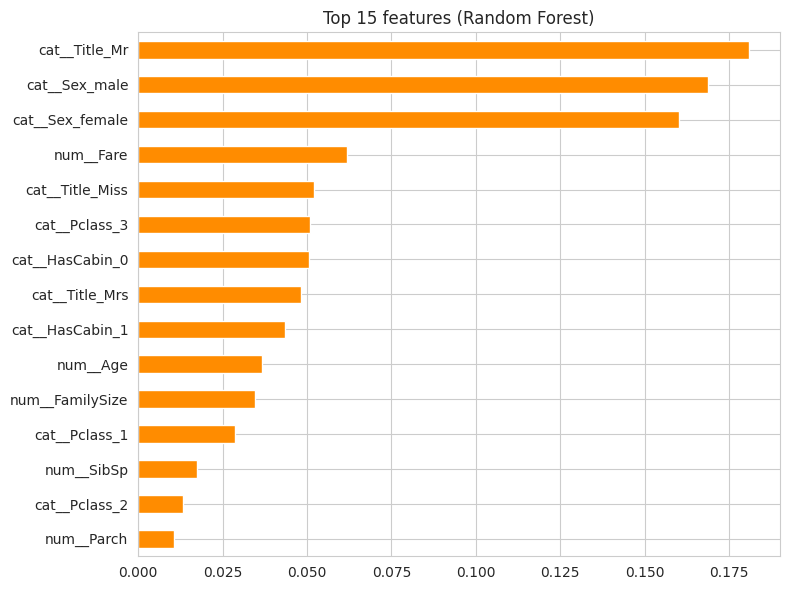

In [21]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = best_model.named_steps["model"].feature_importances_

imp = (pd.Series(importances, index=feature_names)
         .sort_values(ascending=False).head(15))

plt.figure(figsize=(8, 6))
imp[::-1].plot(kind="barh", color="darkorange")
plt.title("Top 15 features (Random Forest)")
plt.tight_layout()
plt.show()

## 11. Save the Model and Make a Prediction

In [22]:
joblib.dump(best_model, "titanic_best_model.joblib")
print("Saved: titanic_best_model.joblib")

# Example: predict for a new passenger
new_passenger = pd.DataFrame([{
    "Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0,
    "Fare": 80.0, "Embarked": "S", "Title": "Miss",
    "FamilySize": 1, "IsAlone": 1, "HasCabin": 1,
}])

loaded = joblib.load("titanic_best_model.joblib")
prob = loaded.predict_proba(new_passenger)[0, 1]
print(f"Survival probability: {prob:.2%}")

Saved: titanic_best_model.joblib
Survival probability: 94.75%


## 12. Optional: Kaggle Submission

If you have the competition's `test.csv`, run this cell to create `submission.csv`.

In [24]:
import os

test_path = next((p for p in ["/kaggle/input/competitions/titanic/test.csv", "test.csv"] if os.path.exists(p)), None)

if test_path:
    kaggle_test = pd.read_csv(test_path)
    ids = kaggle_test["PassengerId"]
    X_kaggle = engineer_features(kaggle_test)
    submission = pd.DataFrame({"PassengerId": ids, "Survived": best_model.predict(X_kaggle)})
    submission.to_csv("submission.csv", index=False)
    print("Saved submission.csv", submission.shape)
else:
    print("test.csv not found. Skipping.")

Saved submission.csv (418, 2)


## 13. Conclusions

**Best model:** Logistic Regression and SVM (RBF) were the top performers. Both reached about 82.7% cross-validated accuracy. On the held-out test set, SVM scored 83.8% and Logistic Regression 83.2%, a gap of one passenger out of 179, so the two are effectively tied. Gradient Boosting (82.4% CV, 82.7% test) was close behind. I would pick **Logistic Regression** as the final model because it matches SVM's accuracy, has the best test ROC-AUC (0.873), and is simple and easy to interpret.

**Key predictors:** The Random Forest feature importance shows that **Title (especially Mr) and Sex** are by far the most important features, followed by **Fare**, **passenger class** (Pclass 3), and **HasCabin**. This matches the EDA: women and children survived at much higher rates ("women and children first"), and wealthier passengers (higher fare, first class, known cabin) had better survival odds. Age and family size contributed less.

**Trade-offs:** Simple models (Logistic Regression, SVM) performed as well as or better than the ensembles (Random Forest, AdaBoost) on this small, mostly categorical dataset, and they are faster and more interpretable. Tree ensembles can capture non-linear patterns but need more data to pay off. The tuned Random Forest improved its CV accuracy to 83.6%, but its test accuracy was only 79.3%, lower than the untuned simple models.

**Limitations:**
- Small dataset (891 rows). The 179-passenger test set means one or two passengers shift accuracy by about 1%, so small differences between models are not meaningful.
- Missing values: Age (about 20%) was imputed with the median, and Cabin (77%) was reduced to a simple HasCabin flag, which loses information.
- Tuning gains did not carry over to the test set, which suggests mild overfitting to the cross-validation folds.
- Results come from a single train/test split.

**Next steps:** Try XGBoost/LightGBM, impute Age using Title or Pclass groups instead of the global median, add more features (ticket groups, deck from cabin, fare per person), tune SVM and Logistic Regression as well, and try voting or stacking ensembles of the top models.
